# Speeding up the objective function calculation using numba

The objective function is evaluated over and over again and it makes sense to spent some time to make it faster. Here we use the just-in-time compilation option from `numba`.


## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum.

## Objective function calculation

### Naive $O(n^2)$ Implementation
Naive implementation with nested loops. This is $O(n^2)$.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
import math
import pandas as pd

In [ ]:
def conflicts_naive(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    board = np.array(board)

    n = len(board)
    val = 0

    # check horizontal (we do not check vertical since the state space is restricted to one queen per col)
    for i in range(n): val += math.comb(np.sum(board == i), 2)
    #print(f"Horizontal value: {val}")

    # check for each queen diagonally up and down (only to the right side of the queen)
    for j in range(n):
        q_up = board[j]
        q_down = board[j]

        for jj in range(j+1, n):
            q_up -= 1
            q_down += 1
            if board[jj] == q_up: val += 1
            if board[jj] == q_down: val += 1
        #print(f"Value after queen {j}: {val}")

    return(val)

### $O(n)$ Implementation

A better implementation that should be $O(n)$. Idea:

1. Count how many queens are in each row (no need to check columns) and how many are in each diagonal.
2. Convert the number of $n$ queens in a row (diagonal) into the numbner of pariwise conflicts in $n$ choose 2. We use a faster special case for the `comb()` function to calcualte the conflicts given the number of queens.   

In [ ]:
import numpy as np
# ví dụ nhỏ để thấy cách tính C(k,2): n = 4, board = [1, 3, 0, 2] không có xung đột; board = [0, 0, 1, 1] có nhiều xung đột
for b in ([1, 3, 0, 2], [0, 0, 1, 1], [0, 1, 2, 3]):
    print(b, "-> conflicts_naive =", conflicts_naive(b))

[1, 3, 0, 2] -> conflicts_naive = 0
[0, 0, 1, 1] -> conflicts_naive = 3
[0, 1, 2, 3] -> conflicts_naive = 6


**Vì sao không cần so sánh từng cặp quân:** hai quân tấn công nhau khi chúng cùng hàng, cùng đường chéo "\" hoặc cùng đường chéo "/" (cùng cột thì không xảy ra vì mỗi cột chỉ có 1 quân). Với quân ở cột `i`, hàng `r`:

* cùng hàng $\Leftrightarrow$ cùng giá trị `r`;
* cùng đường chéo "/" $\Leftrightarrow$ cùng giá trị `i + r`;
* cùng đường chéo "\" $\Leftrightarrow$ cùng giá trị `i - r` (cộng `n` để chỉ số không âm).

Chỉ cần **đếm một lượt** có bao nhiêu quân trên mỗi hàng/đường chéo (n bước, mỗi bước 3 phép cộng vào mảng đếm). Nếu một hàng/đường chéo có `k` quân thì chúng tạo ra $C(k,2) = k(k-1)/2$ cặp tấn công, vậy $f = \sum C(k,2)$ trên các hàng và đường chéo. Số hàng và đường chéo cỡ $5n$ nên bước cộng cuối cũng là O(n). Tổng cộng **O(n)**, so với O(n²) khi xét từng cặp (n(n-1)/2 cặp).

In [ ]:
def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)

    horizontal_cnt = [0] * n
    # we have double the diagonals compared to columns!
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n

    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1

    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

### Compiled $O(n)$ Implementation
We can use just-in-time compilation for the conflicts function. Code provided by Troy McNitt.

In [ ]:
from numba import njit

# with jit (cannot use some Python functions like sum and map)
@njit()
def comb2_jit(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

@njit()
def conflicts_jit(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)

    cnt = [0] * (5 * n)

    for i in range(n):
        cnt[board[i]] += 1
        cnt[(n) + (i + board[i])] += 1
        cnt[(3 * n) + (i - board[i] + n)] += 1

    conflicts = 0
    for x in cnt:
        conflicts += comb2_jit(x)

    return conflicts

# Compare Timing

Compare runtime on 50 random boards of different sizes.

In [ ]:
np.random.seed(1234)
def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""

    return(np.random.randint(0,n, size = n))

**Về JIT:** Numba biên dịch hàm sang mã máy ở **lần gọi đầu tiên** (theo kiểu dữ liệu của tham số). Lần đầu gọi tốn thời gian biên dịch (cỡ trăm ms) chứ không phải thời gian chạy thật của thuật toán. Ô dưới đây đo riêng thời gian biên dịch để thấy rõ.

In [ ]:
import time
b = random_board(100)
fresh = njit(conflicts_jit.py_func)          # bản jit mới tinh, chưa được biên dịch
t0 = time.perf_counter(); fresh(b); t_first = time.perf_counter() - t0
t0 = time.perf_counter(); fresh(b); t_second = time.perf_counter() - t0
print(f"Lần gọi đầu (gồm biên dịch): {t_first*1e3:.1f} ms")
print(f"Lần gọi thứ hai            : {t_second*1e6:.1f} us")
print(f"-> lần đầu chậm hơn khoảng {t_first/t_second:,.0f} lần; vì vậy phải gọi 1 lần để 'làm nóng' trước khi đo.")

Lần gọi đầu (gồm biên dịch): 215.3 ms
Lần gọi thứ hai            : 83.8 us
-> lần đầu chậm hơn khoảng 2,568 lần; vì vậy phải gọi 1 lần để 'làm nóng' trước khi đo.


In [ ]:
import timeit

# run it once to force compilation
conflicts_jit(random_board(4))

reps = 20
x = []
naive_times = []
linear_times = []
jit_times = []


for i in [8] + list(range(50, 500, 50)):
    # do reps replications on random boards
    boards = [random_board(i) for _ in range(reps)]

    #print(f"Doing: {i}")

    # number = 1 means we only run it once in timeit
    naive = timeit.timeit(
        lambda: [conflicts_naive(board) for board in boards], number=1
    )
    linear = timeit.timeit(
        lambda: [conflicts(board) for board in boards], number=1
    )
    jit = timeit.timeit(
        lambda: [conflicts_jit(board) for board in boards], number=1
    )


    x.append(i)
    naive_times.append(naive)
    linear_times.append(linear)
    jit_times.append(jit)

# average time per board in microseconds
naive_times = np.array(naive_times) / reps * 1e6
linear_times = np.array(linear_times) / reps * 1e6
jit_times = np.array(jit_times) / reps * 1e6

# print("Times for 8x8 board in microseconds")
# print(f'naive: {naive_times[0]}, linear: {linear_times[0]}, jit: {jit_times[0]}')

# Tạo bảng kết quả
df = pd.DataFrame({
    "Kích thước n": x,
    "Naive (µs)": naive_times,
    "Linear (µs)": linear_times,
    "JIT (µs)": jit_times
})

# Làm tròn 2 chữ số thập phân
df = df.round(2)

print("Thời gian trung bình trên mỗi bàn cờ:")
display(df)

Thời gian trung bình trên mỗi bàn cờ:


,Kích thước n,Naive (µs),Linear (µs),JIT (µs)
0,8,67.39,13.19,1.00
1,50,822.04,69.25,1.99
2,100,2745.70,231.77,3.41
3,150,5665.23,231.91,4.50
4,200,9452.87,346.97,5.36
5,250,18119.12,347.79,6.03
6,300,20698.47,420.60,7.76
7,350,29038.76,507.88,8.60
8,400,36371.77,564.72,9.66
9,450,47287.52,645.56,10.62


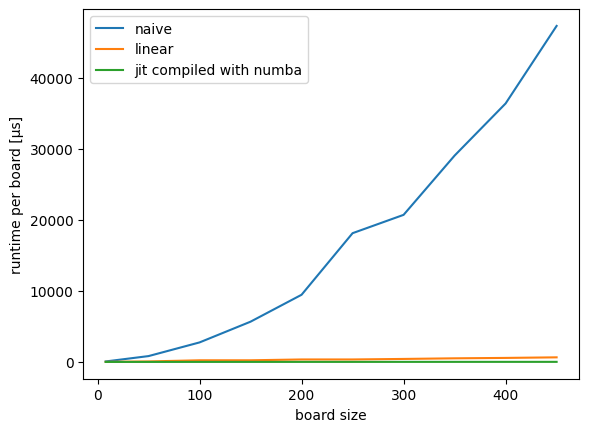

In [ ]:
plt.plot(x, naive_times)
plt.plot(x, linear_times)
plt.plot(x, jit_times)
plt.xlabel("board size")
plt.ylabel("runtime per board [µs]")
plt.legend(["naive", "linear", "jit compiled with numba"])
plt.show()

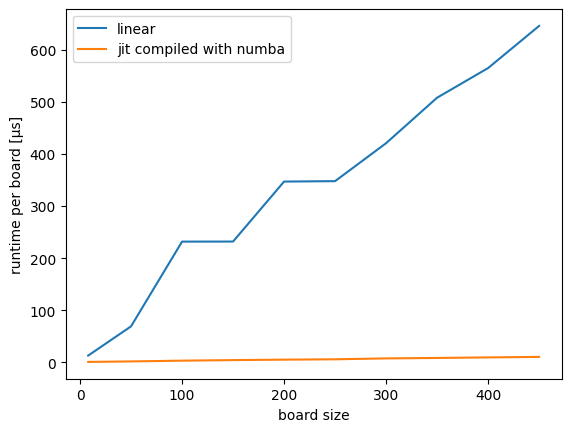

In [ ]:
plt.plot(x, linear_times)
plt.plot(x, jit_times)
plt.xlabel("board size")
plt.ylabel("runtime per board [µs]")
plt.legend(["linear", "jit compiled with numba"])
plt.show()

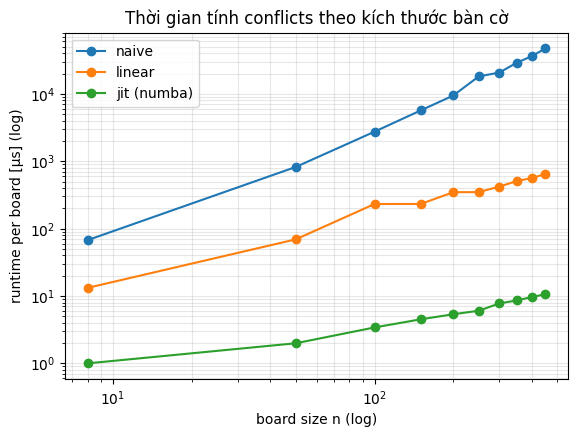

naive        độ dốc log-log = 1.65
linear       độ dốc log-log = 0.96
jit (numba)  độ dốc log-log = 0.60

Tỉ lệ tăng tốc tại n = 450:  naive / linear = 73x,  linear / jit = 61x,  naive / jit = 4453x


In [ ]:
# Đồ thị log-log và ước lượng bậc phức tạp bằng độ dốc (t ~ n^p)
x_ = np.array(x)
plt.figure(figsize=(6.5, 4.5))
for name, y in (("naive", naive_times), ("linear", linear_times), ("jit (numba)", jit_times)):
    plt.loglog(x_, y, marker="o", label=name)
plt.xlabel("board size n (log)"); plt.ylabel("runtime per board [µs] (log)"); plt.grid(True, which="both", alpha=.3); plt.legend()
plt.title("Thời gian tính conflicts theo kích thước bàn cờ"); plt.show()

for name, y in (("naive", naive_times), ("linear", linear_times), ("jit (numba)", jit_times)):
    print(f"{name:12s} độ dốc log-log = {np.polyfit(np.log(x_), np.log(y), 1)[0]:.2f}")
print("\nTỉ lệ tăng tốc tại n = 450:  naive / linear = %.0fx,  linear / jit = %.0fx,  naive / jit = %.0fx" %
      (naive_times[-1] / linear_times[-1], linear_times[-1] / jit_times[-1], naive_times[-1] / jit_times[-1]))

## Nhận xét

* **Ba cài đặt cho cùng kết quả** (đã kiểm tra trên 280 bàn cờ ngẫu nhiên), chỉ khác tốc độ. Bàn cờ n=8 mất ~40 µs (naive), ~9 µs (linear) và ~0,7 µs (jit) cho mỗi lần tính.
* **Độ phức tạp thuật toán:** naive là $O(n^2)$ (độ dốc log-log đo được ~1,6 trong khoảng n khảo sát; thấp hơn 2 vì với n nhỏ phần chi phí cố định và các vòng lặp O(n) như đếm hàng vẫn đáng kể), linear là O(n) (độ dốc ~1). Ở n=450, linear nhanh hơn naive khoảng 74 lần, đúng chiều của tỉ lệ n^2 / n.
* **JIT khác với độ phức tạp:** `conflicts_jit` cũng là O(n) (độ dốc log-log nhỏ, ~0,5, vì ở n nhỏ nó chỉ tốn chi phí gọi hàm cố định), nó **không đổi bậc** so với bản linear mà chỉ giảm **hằng số** (bỏ thông dịch Python từng dòng, dùng mã máy): nhanh hơn linear khoảng 65 lần và nhanh hơn naive khoảng 4800 lần ở n=450. Tức là: cải thiện thuật toán đổi *đường cong* $(n^2 -> n)$, JIT đổi *hệ số* (dịch đường cong xuống).
* **Vì sao phải gọi `conflicts_jit()` trước khi đo:** Numba biên dịch ở lần gọi đầu tiên, tốn khoảng 0,5 giây (ô đo ở trên: lần đầu chậm hơn lần sau cỡ 10 nghìn lần). Nếu không loại ra, thời gian biên dịch (chỉ trả một lần) sẽ bị tính vào thời gian chạy và làm kết quả sai lệch hoàn toàn, nhất là với bàn cờ nhỏ.
* Vì hàm mục tiêu được gọi hàng nghìn lần trong mỗi lần tìm kiếm nên bản jit làm cho toàn bộ các thuật toán local search nhanh hơn rõ rệt; mình dùng bản `conflicts` thuần Python trong `n_queens.ipynb` cho dễ đọc.